# Olist — слой Bronze

Bronze — первая остановка данных в хранилище: исходные CSV без изменений, переложенные в Parquet
и дополненные техническими полями загрузки. Ноутбук проверяет, что загрузка полная и ничего не исказила,
и сравнивает форматы CSV и Parquet.

**Данные:** `data/bronze/olist/` и манифест загрузки `_manifest.json`, созданные скриптом
`python -m src.ingestion.bronze_olist`. Правила слоя — в [bronze.md](../../../docs/architecture/bronze.md).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

In [2]:
import csv
import json
import time

import pyarrow.parquet as pq

from src.utils.config import BRONZE_DIR, OLIST_TABLES, RAW_DIR, SILVER_DIR

BRONZE = BRONZE_DIR / "olist"
RAW = RAW_DIR / "olist"
manifest = json.loads((BRONZE / "_manifest.json").read_text(encoding="utf-8"))
{k: manifest[k] for k in ("source", "batch_id", "ingestion_timestamp")}

{'source': 'olist',
 'batch_id': '20261107T205057Z',
 'ingestion_timestamp': '2026-11-07T20:50:57+00:00'}

## Полнота загрузки

**Вопрос:** все ли записи CSV попали в Parquet?
Число записей CSV считается независимым парсером (модуль `csv` из Python), а не самим Spark.

In [3]:
load = pd.DataFrame(manifest["tables"])[["table", "source_file", "csv_records", "parquet_rows", "status"]]
load["полнота"] = load.parquet_rows / load.csv_records
st.as_pct(load, ["полнота"], 2)

,table,source_file,csv_records,parquet_rows,status,полнота
0,customers,olist_customers_dataset.csv,99441,99441,OK,"100,00%"
1,orders,olist_orders_dataset.csv,99441,99441,OK,"100,00%"
2,order_items,olist_order_items_dataset.csv,112650,112650,OK,"100,00%"
3,products,olist_products_dataset.csv,32951,32951,OK,"100,00%"
4,sellers,olist_sellers_dataset.csv,3095,3095,OK,"100,00%"
5,payments,olist_order_payments_dataset.csv,103886,103886,OK,"100,00%"
6,reviews,olist_order_reviews_dataset.csv,99224,99224,OK,"100,00%"
7,geolocation,olist_geolocation_dataset.csv,1000163,1000163,OK,"100,00%"
8,category_translation,product_category_name_translation.csv,71,71,OK,"100,00%"


**Формула**

$$\text{полнота}_T = \frac{n^{\text{parquet}}_T}{n^{\text{csv}}_T}$$

где $n^{\text{csv}}_T$ — число записей в CSV-файле таблицы $T$ по независимому парсеру,
$n^{\text{parquet}}_T$ — число строк в Parquet после загрузки.

**Пример расчёта** (отзывы)

$$\frac{99\,224}{99\,224} = 1 \;(100\%)$$

**Вывод.** Все 9 таблиц загружены полностью: 1 550 922 записи, расхождений нет. При расхождении загрузка
завершилась бы ошибкой, а не записала неполные данные.

## Многострочные записи

**Вопрос:** почему число строк в файле отзывов не совпадает с числом отзывов?

In [4]:
path = RAW / OLIST_TABLES["reviews"]["file"]
with open(path, encoding="utf-8") as f:
    physical = sum(1 for _ in f) - 1
with open(path, newline="", encoding="utf-8") as f:
    records = sum(1 for _ in csv.reader(f)) - 1
reviews = pd.read_parquet(BRONZE / "reviews", columns=["review_id", "review_comment_message"])
multiline = reviews.review_comment_message.str.contains("\n", na=False)
pd.DataFrame({"строк в файле": [physical], "записей CSV": [records], "лишних строк": [physical - records],
              "отзывов с переносом строки": [int(multiline.sum())]})

,строк в файле,записей CSV,лишних строк,отзывов с переносом строки
0,104719,99224,5495,3852


In [5]:
example = reviews.loc[multiline, "review_comment_message"].iloc[0]
print(repr(example))

'Mas um pouco ,travando...pelo valor ta Boa.\n'


**Формула**

$$\text{лишних строк} = L - N = \sum_{i=1}^{N} b_i$$

где $L$ — число физических строк файла, $N$ — число записей, $b_i$ — число переносов строки внутри
кавычек в записи $i$.

**Пример расчёта**

$$104\,719 - 99\,224 = 5\,495$$

**Вывод.** В комментариях к отзывам 5 495 переносов строки внутри кавычек. Если читать файл построчно
(режим Spark по умолчанию), каждый такой перенос превратится в лишнюю «запись» с мусором в колонках.
Поэтому Bronze читает CSV в режиме `multiLine` и сверяет число записей с независимым парсером.

## Структура и технические поля

**Вопрос:** что хранит Bronze, кроме исходных колонок?

In [6]:
schema = pq.read_schema(next((BRONZE / "orders").glob("*.parquet")))
pd.DataFrame({"колонка": schema.names, "тип": [str(t) for t in schema.types]})

,колонка,тип
0,order_id,string
1,customer_id,string
2,order_status,string
3,order_purchase_timestamp,string
4,order_approved_at,string
5,order_delivered_carrier_date,string
6,order_delivered_customer_date,string
7,order_estimated_delivery_date,string
8,_source,string
9,_source_file,string


In [7]:
pd.read_parquet(BRONZE / "orders").head(3).T

,0,1,2
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49
order_approved_at,2017-10-02 11:07:15,2018-07-26 03:24:27,2018-08-08 08:55:23
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00
_source,olist,olist,olist
_source_file,olist_orders_dataset.csv,olist_orders_dataset.csv,olist_orders_dataset.csv


**Вывод.**
- Все исходные колонки хранятся строками: Bronze не угадывает типы, чтобы не потерять ведущие нули и не
  исказить даты. Типы задаются явно в Silver.
- Четыре технических поля (`_source`, `_source_file`, `_ingestion_timestamp`, `_batch_id`) позволяют
  для любой строки сказать, из какого файла и какой загрузки она пришла.

## Сжатие: CSV и Parquet

**Вопрос:** сколько места экономит переход на Parquet?

In [8]:
sizes = pd.DataFrame([{
    "таблица": name,
    "CSV, МБ": (RAW / meta["file"]).stat().st_size / 1e6,
    "Parquet, МБ": sum(p.stat().st_size for p in (BRONZE / name).glob("*.parquet")) / 1e6,
} for name, meta in OLIST_TABLES.items()])
sizes["сжатие, раз"] = sizes["CSV, МБ"] / sizes["Parquet, МБ"]
sizes = sizes.sort_values("CSV, МБ", ascending=False)
total = sizes[["CSV, МБ", "Parquet, МБ"]].sum()
print(f"Всего: CSV {st.num(total['CSV, МБ'], 1)} МБ, Parquet {st.num(total['Parquet, МБ'], 1)} МБ, "
      f"сжатие {st.num(total['CSV, МБ'] / total['Parquet, МБ'], 2)} раза")
sizes

Всего: CSV 126,2 МБ, Parquet 64,8 МБ, сжатие 1,95 раза


,таблица,"CSV, МБ","Parquet, МБ","сжатие, раз"
7,geolocation,"61,27","25,64","2,39"
1,orders,"17,65","10,45","1,69"
2,order_items,"15,44","6,79","2,27"
6,reviews,"14,45","9,53","1,52"
0,customers,"9,03","6,99","1,29"
5,payments,"5,78","3,85","1,50"
3,products,"2,38","1,37","1,74"
4,sellers,"0,17","0,13","1,32"
8,category_translation,"0,00","0,00","0,57"


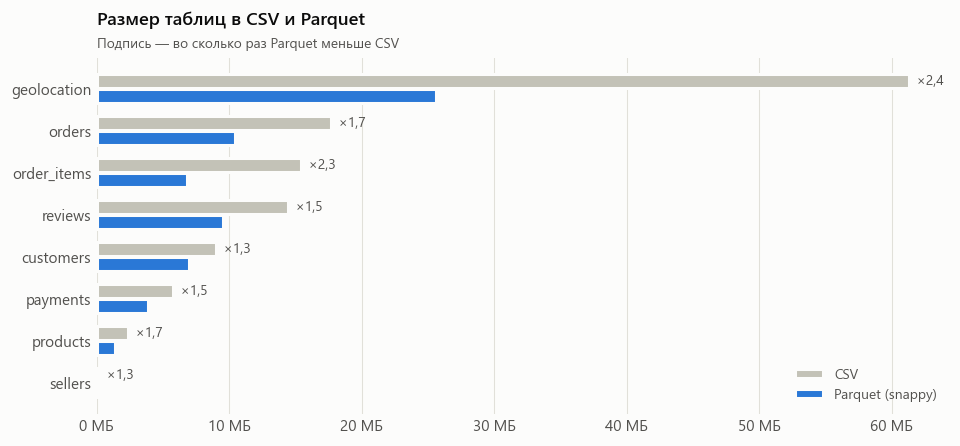

In [9]:
view = sizes[sizes["CSV, МБ"] > 0.1]
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(view))[::-1]
ax.barh(y + 0.18, view["CSV, МБ"], height=0.34, color=st.CONTEXT, label="CSV", edgecolor=st.SURFACE, linewidth=2)
ax.barh(y - 0.18, view["Parquet, МБ"], height=0.34, color=st.BLUE, label="Parquet (snappy)", edgecolor=st.SURFACE, linewidth=2)
for yi, (_, r) in zip(y, view.iterrows()):
    ax.text(r["CSV, МБ"], yi + 0.18, f"  ×{st.num(r['сжатие, раз'], 1)}", va="center", fontsize=9, color=st.INK_2)
ax.set_yticks(y, view["таблица"])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{st.num(v)} МБ"))
ax.legend(loc="lower right")
st.titles(ax, "Размер таблиц в CSV и Parquet", "Подпись — во сколько раз Parquet меньше CSV")
st.save(fig, "olist_bronze_01_sizes")
plt.show()

**Формула**

$$k = \frac{S_{\text{csv}}}{S_{\text{parquet}}}$$

где $S$ — размер файлов таблицы в байтах.

**Пример расчёта** (геолокация и все таблицы)

$$k_{\text{geolocation}} = \frac{61{,}27}{25{,}64} \approx 2{,}39, \qquad k_{\text{всего}} = \frac{126{,}2}{64{,}8} \approx 1{,}95$$

**Вывод.**
- Parquet со сжатием snappy в среднем вдвое меньше CSV. Лучше всего сжимаются таблицы с повторяющимися
  значениями: геолокация (×2,4) и товарные позиции (×2,3). Хуже — таблицы из случайных хэшей
  (покупатели ×1,3): хэш почти не сжимается.
- Крошечный справочник перевода категорий в Parquet даже больше CSV: служебные метаданные формата
  (схема, статистика) весят больше самих 71 строки.

## Скорость чтения

**Вопрос:** быстрее ли читать Parquet, чем CSV?
Каждый вариант запускается три раза, берётся лучшее время.

In [10]:
def best_time(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t)
    return min(times)

csv_path = RAW / OLIST_TABLES["order_items"]["file"]
bench = pd.DataFrame([
    {"вариант": "CSV, вся таблица", "секунд": best_time(lambda: pd.read_csv(csv_path))},
    {"вариант": "Bronze Parquet, вся таблица (строки)", "секунд": best_time(lambda: pd.read_parquet(BRONZE / "order_items"))},
    {"вариант": "Silver Parquet, вся таблица (типы)", "секунд": best_time(lambda: pd.read_parquet(SILVER_DIR / "olist" / "order_items"))},
    {"вариант": "Bronze Parquet, одна колонка", "секунд": best_time(lambda: pd.read_parquet(BRONZE / "order_items", columns=["price"]))},
    {"вариант": "CSV, одна колонка", "секунд": best_time(lambda: pd.read_csv(csv_path, usecols=["price"]))},
])
bench["относительно CSV"] = bench["секунд"] / bench["секунд"].iloc[0]
bench

,вариант,секунд,относительно CSV
0,"CSV, вся таблица","0,16","1,00"
1,"Bronze Parquet, вся таблица (строки)","0,07","0,45"
2,"Silver Parquet, вся таблица (типы)","0,09","0,55"
3,"Bronze Parquet, одна колонка","0,01","0,05"
4,"CSV, одна колонка","0,06","0,37"


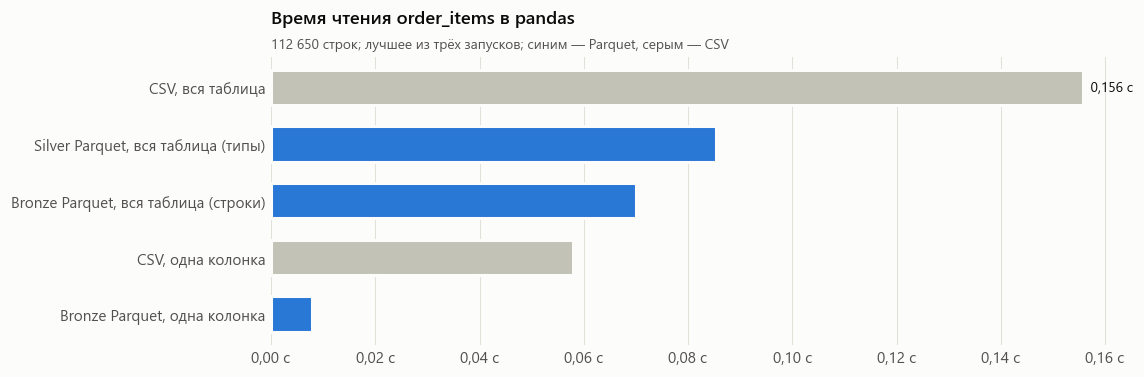

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.4))
order = bench.sort_values("секунд", ascending=False)
st.hbar(ax, order["вариант"], order["секунд"], highlight=[v for v in order["вариант"] if "Parquet" in v],
        fmt=lambda v: f"{st.num(v, 3)} с")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{st.num(v, 2)} с"))
st.titles(ax, "Время чтения order_items в pandas", "112 650 строк; лучшее из трёх запусков; синим — Parquet, серым — CSV")
st.save(fig, "olist_bronze_02_read_speed")
plt.show()

**Вывод.**
- Вся таблица из Parquet читается **примерно вдвое быстрее** CSV: не нужно разбирать текст и угадывать типы.
- Самый большой выигрыш — при чтении **части колонок**: формат колоночный, одна колонка читается
  в 10–15 раз быстрее полного CSV и в несколько раз быстрее той же колонки из CSV
  (CSV всё равно приходится прочитать целиком, чтобы найти нужное поле в каждой строке).
- Типизированный Silver читается примерно так же быстро, как Bronze: выигрыш от компактных чисел
  компенсируется более сложными типами (`decimal`, дата и время).
- Точные значения меняются от запуска к запуску; на таблицах такого размера все варианты укладываются в доли
  секунды. Главные плюсы Parquet здесь — схема, хранимая вместе с данными, сжатие и чтение по колонкам.

## Итоги

| Проверка | Результат |
|---|---|
| Полнота загрузки | 9 из 9 таблиц, 100% записей |
| Многострочные поля | 5 495 переносов в отзывах обработаны режимом `multiLine` |
| Типы | все исходные колонки — строки, типизация в Silver |
| Прослеживаемость | 4 технических поля в каждой строке |
| Сжатие | Parquet в ~2 раза меньше CSV |
| Скорость | вся таблица ~2 раза быстрее CSV, одна колонка — в 10–15 раз |